In [1]:
!pip -q install scipy numpy pandas scikit-learn matplotlib seaborn

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from IPython.display import display

path = Path("Unrelated100_RestTask.mat")
assert path.exists(), f"Upload {path.name} to Colab Files first"
mat = loadmat(str(path), variable_names=["subALL"], struct_as_record=False, squeeze_me=True)
subjects = np.atleast_1d(mat["subALL"]).ravel()
assert len(subjects) == 31
ids = [str(s.ID) for s in subjects]
assert len(set(ids)) == len(ids)
assert all(np.asarray(s.task.Mean_ROIts).shape == (3880, 180) for s in subjects)
assert all(np.isfinite(s.task.Mean_ROIts).all() for s in subjects)
print('Subjects:',len(subjects), 'ROIs:', 180, 'TR:',0.72)

Subjects: 31 ROIs: 180 TR: 0.72


In [3]:
TR = 0.72
HRF_SHIFT_SECONDS = 5.0
TASK_ORDER = ["EMO", "GAM", "LAN", "MOT", "REL", "SOC", "WM"]  # CANDIDATE, NOT VERIFIED
RUN_ORDER = ["RL", "LR"]  # BETTER-SUPPORTED CANDIDATE from EV-versus-boxcar overlap; verify export script
TASK_ORDER_CONFIRMED = False  # Set True ONLY after verifying original concatenation
RUN_ORDER_CONFIRMED = False   # Set True ONLY after verifying each task run order

# 0-based indices, to be populated ONLY from the original ROI extraction/parcellation script.
ROI_GROUPS = None  # e.g. {'cortex': [...100...], 'subcortex':[...54...], 'cerebellum':[...26...]}
ROI_ATLAS_CONFIRMED = False

TASK_KEYS = {
    'WM': {'0back':['X0bk_body','X0bk_faces','X0bk_places','X0bk_tools'],
           '2back':['X2bk_body','X2bk_faces','X2bk_places','X2bk_tools']},
    'GAM': {'win':['Win'], 'loss':['Loss']},
    'REL': {'relation':['Relation'], 'match':['Match']},
    'LAN': {'story':['Story'], 'math':['Math']},
    'MOT': {'left_hand':['Lh'], 'right_hand':['Rh'], 'left_foot':['Lf'],
            'right_foot':['Rf'], 'tongue':['T']},
    'EMO': {'fear':['Fear'], 'neutral':['Neut']},
}
LENGTH_KEYS = {'WM':'WM_0bk', 'GAM':'GAM_Win_event','REL':'REL_Relation',
               'LAN':'LAN_Story','MOT':'MOT_AnyMovement','EMO':'EMO_Fear'}

def task_lengths(subject):
    d = {t:len(np.asarray(getattr(subject.boxcar, key)).ravel()) for t,key in LENGTH_KEYS.items()}
    d['SOC'] = subject.task.Mean_ROIts.shape[0] - sum(d.values())
    return d

lengths = task_lengths(subjects[0]); print('Task lengths:',lengths)
print('Sum:',sum(lengths.values()))
assert sum(lengths.values()) == 3880 and lengths['SOC'] == 548
assert set(TASK_ORDER) == set(lengths)
assert set(RUN_ORDER) == {'LR','RL'}
assert all(all(task_lengths(s)[k] == lengths[k] for k in lengths) for s in subjects)

def boundaries(lengths, task_order):
    cursor=0; out={}
    for t in task_order:
        n=lengths[t]
        if n % 2: raise ValueError(f'Cannot assume equal run length for {t}')
        out[t]={'start':cursor, 'run_length':n//2, 'end':cursor+n}
        cursor+=n
    assert cursor==3880
    return out
bounds=boundaries(lengths,TASK_ORDER)
display(pd.DataFrame.from_dict(bounds,orient='index'))

Task lengths: {'WM': 810, 'GAM': 506, 'REL': 464, 'LAN': 632, 'MOT': 568, 'EMO': 352, 'SOC': 548}
Sum: 3880


,start,run_length,end
EMO,0,176,352
GAM,352,253,858
LAN,858,316,1490
MOT,1490,284,2058
REL,2058,232,2522
SOC,2522,274,3070
WM,3070,405,3880


In [4]:
def as_events(x):
    a=np.asarray(x,dtype=float)
    if a.ndim==1: a=a.reshape(1,-1)
    if a.ndim!=2 or a.shape[1]<2: raise ValueError(f'Bad event array: {a.shape}')
    return a

def event_mask(ev, keys, run_len, shift_sec=0):
    mask=np.zeros(run_len,dtype=bool)
    for key in keys:
        if not hasattr(ev,key): raise KeyError(key)
        for onset,duration,*_ in as_events(getattr(ev,key)):
            lo=int(np.floor((onset+shift_sec)/TR)); hi=int(np.ceil((onset+duration+shift_sec)/TR))
            if hi<=0 or lo>=run_len:continue
            mask[max(lo,0):min(hi,run_len)]=True
    return mask

BOXCAR_PAIRS = {
    'WM': {'0back':'WM_0bk','2back':'WM_2bk'},
    'GAM': {'win':'GAM_Win_event','loss':'GAM_Loss_event'},
    'REL': {'relation':'REL_Relation','match':'REL_Match'},
    'LAN': {'story':'LAN_Story','math':'LAN_Math'},
    'EMO': {'fear':'EMO_Fear','neutral':'EMO_Neut'},
}

def agreement(subject, task, run_order):
    n=lengths[task]; k=n//2
    rows=[]
    for label,boxkey in BOXCAR_PAIRS[task].items():
        actual=np.asarray(getattr(subject.boxcar,boxkey)).ravel().astype(bool)
        predicted=np.concatenate([
            event_mask(getattr(getattr(subject.EV,task),run),TASK_KEYS[task][label],k)
            for run in run_order
        ])
        intersection=np.sum(actual & predicted); union=np.sum(actual | predicted)
        rows.append((label, intersection/union if union else np.nan))
    return dict(rows)

rows=[]
for task in BOXCAR_PAIRS:
    for order in [('LR','RL'),('RL','LR')]:
        val=agreement(subjects[0],task,order)
        rows.append({'task':task,'run_order':'+'.join(order),**val,
                     'mean_IoU':np.nanmean(list(val.values()))})
display(pd.DataFrame(rows).fillna(''))
print('NOTE: Motor has only AnyMovement boxcar. Its five conditions require original EV validation.')

,task,run_order,0back,2back,mean_IoU,win,loss,relation,match,story,math,fear,neutral
0,WM,LR+RL,0.585859,0.592875,0.589367,,,,,,,,
1,WM,RL+LR,0.974843,0.981013,0.977928,,,,,,,,
2,GAM,LR+RL,,,0.304117,0.333333,0.2749,,,,,,
3,GAM,RL+LR,,,0.649485,0.649485,0.649485,,,,,,
4,REL,LR+RL,,,0.486730,,,0.491979,0.481481,,,,
5,REL,RL+LR,,,0.954617,,,0.964789,0.944444,,,,
6,LAN,LR+RL,,,0.484425,,,,,0.47,0.498851,,
7,LAN,RL+LR,,,0.978138,,,,,0.986486,0.969789,,
8,EMO,LR+RL,,,0.926531,,,,,,,0.878378,0.974684
9,EMO,RL+LR,,,0.926531,,,,,,,0.878378,0.974684


NOTE: Motor has only AnyMovement boxcar. Its five conditions require original EV validation.


In [6]:
def extract_blocks(subjects, shift=5.0, min_timepoints=6):
    if not (TASK_ORDER_CONFIRMED and RUN_ORDER_CONFIRMED):
        raise RuntimeError('Confirm TASK_ORDER and RUN_ORDER from the original MATLAB export before extraction.')
    rows=[]; feats=[]; dropped=[]
    for s in subjects:
        sid=str(s.ID); full=np.asarray(s.task.Mean_ROIts,dtype=float)
        b=boundaries(task_lengths(s),TASK_ORDER)
        for task,labmap in TASK_KEYS.items():
            start=b[task]['start']; run_n=b[task]['run_length']
            for j,run in enumerate(RUN_ORDER):
                run_start=start+j*run_n
                sig=full[run_start:run_start+run_n]
                mean=sig.mean(axis=0); sd=sig.std(axis=0)
                z=(sig-mean)/np.where(sd>1e-10,sd,1.)
                ev=getattr(getattr(s.EV,task),run)
                for label,keys in labmap.items():
                    for key in keys:
                        for event_no,event in enumerate(as_events(getattr(ev,key))):
                            onset,dur=event[:2]
                            a=int(np.ceil((onset+shift)/TR)); e=int(np.ceil((onset+shift+dur)/TR))
                            info={'subject':sid,'task':task,'run':run,'label':label,
                                  'event':key,'event_number':event_no, 'onset':onset,'duration':dur,
                                  'start_tr':a,'end_tr':e}
                            if not np.isfinite([onset,dur]).all() or a<0 or e>run_n or e-a<min_timepoints:
                                dropped.append({**info,'reason':'invalid/truncated/short shifted window'}); continue
                            vector=z[a:e].mean(axis=0)
                            if not np.isfinite(vector).all():
                                dropped.append({**info,'reason':'nonfinite feature'});continue
                            feats.append(vector.astype('float32'));rows.append(info)
    if not feats: raise RuntimeError('No valid blocks')
    X=np.stack(feats); meta=pd.DataFrame(rows); discarded=pd.DataFrame(dropped)
    assert X.shape[1]==180 and len(X)==len(meta)
    assert len(set(meta.subject))==len(subjects)
    return X,meta,discarded

# Uncomment ONLY after reviewing Section 2 configuration and confirming its mappings:
    X,meta,dropped=extract_blocks(subjects)
    print('X:',X.shape, 'subjects:',meta.subject.nunique(), 'dropped:',len(dropped))
    display(meta.groupby(['task','label']).size().unstack(fill_value=0))
    np.save('hcp_features_activity.npy',X)
    meta.to_csv('hcp_block_metadata.csv',index=False)
    dropped.to_csv('hcp_dropped_events.csv',index=False)


In [7]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

SEED=42
MODEL_SPECS={
 'dummy': (DummyClassifier(strategy='most_frequent'), None, None),
 'logreg': (Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=5000,random_state=SEED))]),
            {'model__C':[.001,.01,.1,1,10,100], 'model__class_weight':[None,'balanced']},'grid'),
 'svm': (Pipeline([('scale',StandardScaler()),('model',LinearSVC(max_iter=15000,random_state=SEED))]),
         {'model__C':[.001,.01,.1,1,10,100], 'model__class_weight':[None,'balanced']},'grid'),
 'rf': (Pipeline([('model',RandomForestClassifier(random_state=SEED,n_jobs=1))]),
        {'model__n_estimators':[200,500], 'model__max_depth':[5,10,None],
         'model__min_samples_leaf':[2,5,10], 'model__max_features':['sqrt',.5],
         'model__class_weight':[None,'balanced']},'random')
}

def nested_cv(X,meta,task,roi_indices,models=('dummy','logreg','svm','rf'),outer_splits=5,inner_splits=4):
    m=meta.loc[meta.task==task].reset_index(drop=True)
    Z=X[np.flatnonzero(meta.task.to_numpy()==task)][:,roi_indices]
    y=m.label.to_numpy();groups=m.subject.to_numpy()
    assert len(Z)==len(m) and np.isfinite(Z).all()
    outer=GroupKFold(n_splits=outer_splits)
    fold_rows=[]; preds=[]; tunes=[]
    for name in models:
        estimator, params, strategy=MODEL_SPECS[name]
        for fold,(tr,te) in enumerate(outer.split(Z,y,groups),1):
            if set(groups[tr]) & set(groups[te]):raise AssertionError('subject leakage')
            if set(np.unique(y[tr]))!=set(np.unique(y)):raise ValueError('Training fold missing a class')
            inner=GroupKFold(n_splits=inner_splits)
            if strategy is None:
                fitted=clone(estimator).fit(Z[tr],y[tr]); best={}
            else:
                cls=GridSearchCV if strategy=='grid' else RandomizedSearchCV
                kw={'estimator':clone(estimator),'param_grid':params} if strategy=='grid' else                    {'estimator':clone(estimator),'param_distributions':params,'n_iter':24,'random_state':SEED}
                search=cls(**kw,cv=inner,scoring='balanced_accuracy',refit=True,n_jobs=-1,error_score='raise')
                search.fit(Z[tr],y[tr],groups=groups[tr]); fitted=search.best_estimator_;best=search.best_params_
            yh=fitted.predict(Z[te])
            fold_rows.append({'task':task,'model':name,'fold':fold,'n_test':len(te),
                              'balanced_accuracy':balanced_accuracy_score(y[te],yh),
                              'macro_f1':f1_score(y[te],yh,average='macro',zero_division=0)})
            tunes.append({'task':task,'model':name,'fold':fold,'params':str(best)})
            for idx,pred in zip(te,yh):
                preds.append({'task':task,'model':name,'fold':fold,'subject':groups[idx],
                              'y_true':y[idx],'y_pred':pred,'block_index':int(m.index[idx])})
    return pd.DataFrame(fold_rows),pd.DataFrame(preds),pd.DataFrame(tunes)

print('Models ready:',list(MODEL_SPECS))

Models ready: ['dummy', 'logreg', 'svm', 'rf']


In [12]:
validation = []

for subject in subjects:
    for task in BOXCAR_PAIRS:
        for order in [('LR', 'RL'), ('RL', 'LR')]:
            scores = agreement(subject, task, order)

            validation.append({
                "subject": str(subject.ID),
                "task": task,
                "run_order": "+".join(order),
                "mean_IoU": np.nanmean(list(scores.values()))
            })

validation_df = pd.DataFrame(validation)

summary = (
    validation_df
    .groupby(["task", "run_order"])["mean_IoU"]
    .agg(["mean", "min", "max"])
    .round(4)
)

display(summary)

print("\nBest-supported run order by task:")
display(
    validation_df
    .groupby(["task", "run_order"])["mean_IoU"]
    .mean()
    .reset_index()
    .sort_values(["task", "mean_IoU"], ascending=[True, False])
)

mean     min     max
task run_order                        
EMO  LR+RL      0.9263  0.9169  0.9295
     RL+LR      0.9267  0.9203  0.9295
GAM  LR+RL      0.3037  0.3014  0.3082
     RL+LR      0.6481  0.6427  0.6546
LAN  LR+RL      0.4994  0.4461  0.5486
     RL+LR      0.9772  0.9630  0.9886
REL  LR+RL      0.4886  0.4748  0.4960
     RL+LR      0.9630  0.9476  0.9717
WM   LR+RL      0.5979  0.5894  0.6013
     RL+LR      0.9920  0.9779  1.0000


Best-supported run order by task:


,task,run_order,mean_IoU
1,EMO,RL+LR,0.926714
0,EMO,LR+RL,0.926310
3,GAM,RL+LR,0.648098
2,GAM,LR+RL,0.303686
5,LAN,RL+LR,0.977163
4,LAN,LR+RL,0.499351
7,REL,RL+LR,0.962952
6,REL,LR+RL,0.488616
9,WM,RL+LR,0.991980
8,WM,LR+RL,0.597899


In [14]:
TASK_ORDER = ["EMO", "GAM", "LAN", "MOT", "REL", "SOC", "WM"]
RUN_ORDER = ["RL", "LR"]

# Set these only if both orders match the original export:
TASK_ORDER_CONFIRMED = True
RUN_ORDER_CONFIRMED = True

In [15]:
X, meta, dropped = extract_blocks(subjects)

print("Feature matrix:", X.shape)
print("Subjects:", meta.subject.nunique())
print("Dropped blocks:", len(dropped))

display(
    meta.groupby(["task", "label"])
    .size()
    .unstack(fill_value=0)
)

Feature matrix: (2810, 180)
Subjects: 31
Dropped blocks: 129


label,0back,2back,fear,left_foot,left_hand,loss,match,math,neutral,relation,right_foot,right_hand,story,tongue,win
task,,,,,,,,,,,,,,,
EMO,0,0,124,0,0,0,0,0,186,0,0,0,0,0,0
GAM,0,0,0,0,0,124,0,0,0,0,0,0,0,0,124
LAN,0,0,0,0,0,0,0,523,0,0,0,0,241,0,0
MOT,0,0,0,124,124,0,0,0,0,0,124,124,0,124,0
REL,0,0,0,0,0,0,186,0,0,186,0,0,0,0,0
WM,248,248,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

feature_file = Path("hcp_features_activity.npy")
metadata_file = Path("hcp_block_metadata.csv")

if feature_file.exists() and metadata_file.exists():
    X = np.load(feature_file)
    meta = pd.read_csv(metadata_file, dtype={"subject": str})
    print("Loaded previously extracted features.")

else:
    if "subjects" not in globals():
        raise RuntimeError(
            "subjects is missing. Run your successful MATLAB loading cell first."
        )

    if not (TASK_ORDER_CONFIRMED and RUN_ORDER_CONFIRMED):
        raise RuntimeError(
            "Task/run mapping must be verified before extraction. "
            "Do not change the confirmation flags without evidence."
        )

    X, meta, dropped = extract_blocks(subjects)

    np.save(feature_file, X)
    meta.to_csv(metadata_file, index=False)

    print("Extracted new block-level features.")

assert X.ndim == 2 and X.shape[1] == 180
assert len(X) == len(meta)
assert np.isfinite(X).all()
assert meta["subject"].astype(str).nunique() == 31
assert {"subject", "task", "label"}.issubset(meta.columns)

print("X:", X.shape)
print("Metadata:", meta.shape)
print("Unique subjects:", meta["subject"].nunique())

display(
    meta.groupby(["task", "label"])
    .size()
    .unstack(fill_value=0)
)

Extracted new block-level features.
X: (2810, 180)
Metadata: (2810, 10)
Unique subjects: 31


label,0back,2back,fear,left_foot,left_hand,loss,match,math,neutral,relation,right_foot,right_hand,story,tongue,win
task,,,,,,,,,,,,,,,
EMO,0,0,124,0,0,0,0,0,186,0,0,0,0,0,0
GAM,0,0,0,0,0,124,0,0,0,0,0,0,0,0,124
LAN,0,0,0,0,0,0,0,523,0,0,0,0,241,0,0
MOT,0,0,0,124,124,0,0,0,0,0,124,124,0,124,0
REL,0,0,0,0,0,0,186,0,0,186,0,0,0,0,0
WM,248,248,0,0,0,0,0,0,0,0,0,0,0,0,0


In [19]:
ROI_GROUPS = {
    "subcortex": np.arange(0, 54),
    "cortex": np.arange(54, 154),
    "cerebellum": np.arange(154, 180)
}

ROI_ATLAS_CONFIRMED = True

In [21]:
print("ROI_ATLAS_CONFIRMED:", ROI_ATLAS_CONFIRMED)
print("ROI_GROUPS:", ROI_GROUPS)

ROI_ATLAS_CONFIRMED: True
ROI_GROUPS: {'subcortex': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53]), 'cortex': array([ 54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,
        67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,
        80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,
        93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105,
       106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118,
       119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131,
       132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144,
       145, 146, 147, 148, 149, 150, 151, 152, 153]), 'cerebellum': array([154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166,
       167, 168, 169, 170, 171, 172, 173, 174, 1

In [31]:
roi_sets = roi_configurations()
for name, indices in roi_sets.items():
    print(f"{name}: {len(indices)} ROIs")

cortex: 100 ROIs
subcortex: 54 ROIs
cerebellum: 26 ROIs
cortex+subcortex: 154 ROIs
cortex+cerebellum: 126 ROIs
all: 180 ROIs


In [32]:
def roi_configurations():
    if not ROI_ATLAS_CONFIRMED or ROI_GROUPS is None:
        raise RuntimeError('ROI atlas mapping is not verified. Populate ROI_GROUPS from extraction metadata.')
    a={key:np.asarray(ROI_GROUPS[key],dtype=int) for key in ['cortex','subcortex','cerebellum']}
    assert (len(a['cortex']),len(a['subcortex']),len(a['cerebellum']))==(100,54,26)
    merged=np.concatenate(list(a.values()))
    assert len(np.unique(merged))==180 and set(merged)==set(range(180))
    return {'cortex':a['cortex'],'subcortex':a['subcortex'],'cerebellum':a['cerebellum'],
            'cortex+subcortex':np.r_[a['cortex'],a['subcortex']],
            'cortex+cerebellum':np.r_[a['cortex'],a['cerebellum']],
            'all':merged}

roi_sets = roi_configurations()
ablation_rows=[]; ablation_preds=[]
for task in TASK_KEYS:
     for roi_name,indices in roi_sets.items():
         f,p,_=nested_cv(X,meta,task,indices,models=('logreg','svm'))
         f['roi_set']=roi_name;p['roi_set']=roi_name
         ablation_rows.append(f);ablation_preds.append(p)
ablation_folds=pd.concat(ablation_rows,ignore_index=True)
ablation_predictions=pd.concat(ablation_preds,ignore_index=True)
ablation_folds.to_csv('roi_ablation_fold_scores.csv',index=False)
ablation_predictions.to_csv('roi_ablation_predictions.csv',index=False)
display(ablation_folds.groupby(['task','roi_set','model'])['balanced_accuracy'].mean())

task  roi_set            model 
EMO   all                logreg    0.679563
                         svm       0.669643
      cerebellum         logreg    0.562500
                         svm       0.566071
      cortex             logreg    0.676190
                                     ...   
WM    cortex+cerebellum  svm       0.570238
      cortex+subcortex   logreg    0.623214
                         svm       0.638095
      subcortex          logreg    0.593750
                         svm       0.583036
Name: balanced_accuracy, Length: 72, dtype: float64

In [33]:
roi_sets = roi_configurations()

ablation_rows = []
ablation_preds = []

for task in TASK_KEYS:
    print(f"\nRunning task: {task}")

    for roi_name, indices in roi_sets.items():
        print(f"  ROI group: {roi_name}")

        f, p, _ = nested_cv(
            X,
            meta,
            task,
            indices,
            models=("logreg", "svm")
        )

        f["roi_set"] = roi_name
        p["roi_set"] = roi_name

        ablation_rows.append(f)
        ablation_preds.append(p)

ablation_folds = pd.concat(
    ablation_rows,
    ignore_index=True
)

ablation_predictions = pd.concat(
    ablation_preds,
    ignore_index=True
)

ablation_folds.to_csv(
    "roi_ablation_fold_scores.csv",
    index=False
)

ablation_predictions.to_csv(
    "roi_ablation_predictions.csv",
    index=False
)

display(
    ablation_folds.groupby(
        ["task", "roi_set", "model"]
    )["balanced_accuracy"].mean()
)


Running task: WM
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all

Running task: GAM
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all

Running task: REL
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all

Running task: LAN
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all

Running task: MOT
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all

Running task: EMO
  ROI group: cortex
  ROI group: subcortex
  ROI group: cerebellum
  ROI group: cortex+subcortex
  ROI group: cortex+cerebellum
  ROI group: all


task  roi_set            model 
EMO   all                logreg    0.679563
                         svm       0.669643
      cerebellum         logreg    0.562500
                         svm       0.566071
      cortex             logreg    0.676190
                                     ...   
WM    cortex+cerebellum  svm       0.570238
      cortex+subcortex   logreg    0.623214
                         svm       0.638095
      subcortex          logreg    0.593750
                         svm       0.583036
Name: balanced_accuracy, Length: 72, dtype: float64

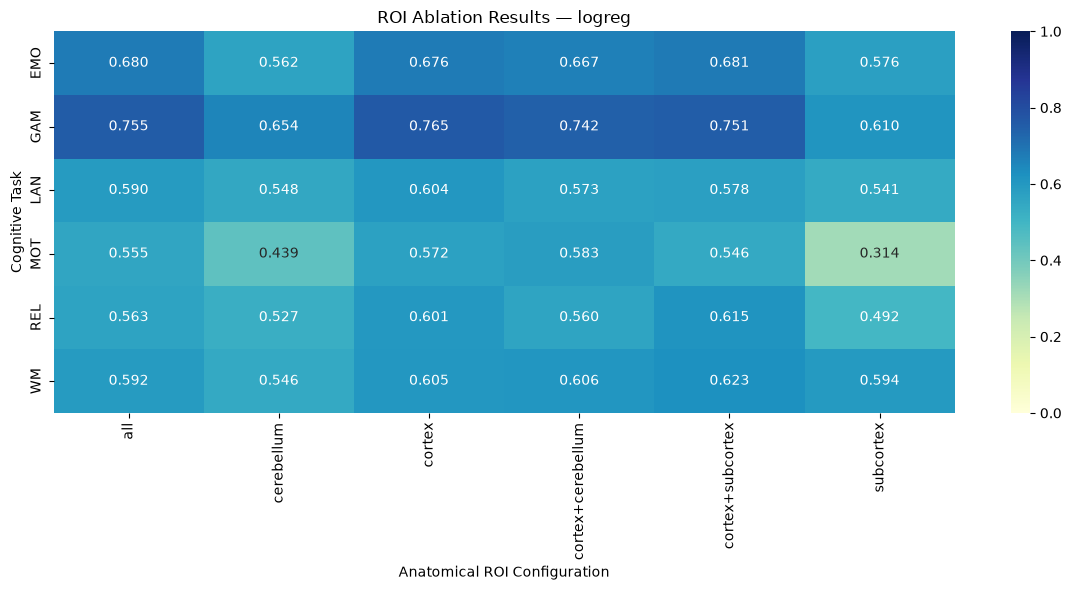

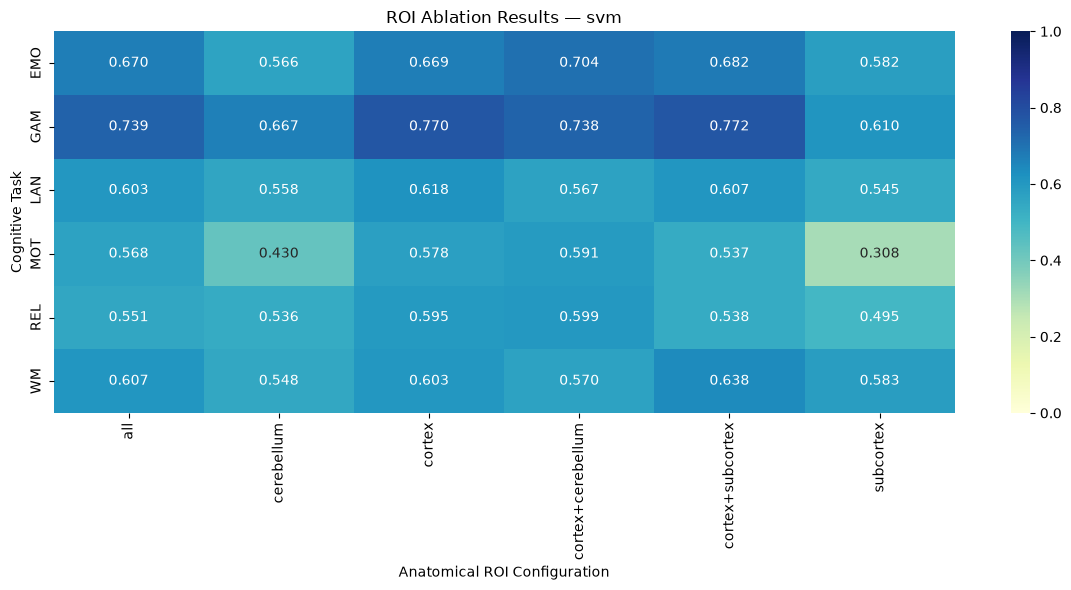

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

summary = (
    ablation_folds
    .groupby(["task", "roi_set", "model"], as_index=False)
    ["balanced_accuracy"]
    .mean()
)

for model in ["logreg", "svm"]:
    subset = summary[summary["model"] == model]

    pivot = subset.pivot(
        index="task",
        columns="roi_set",
        values="balanced_accuracy"
    )

    plt.figure(figsize=(12, 6))

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1
    )

    plt.title(f"ROI Ablation Results — {model}")
    plt.ylabel("Cognitive Task")
    plt.xlabel("Anatomical ROI Configuration")
    plt.tight_layout()
    plt.show()

In [43]:
print("full_folds exists:", "full_folds" in globals())
print("full_preds exists:", "full_preds" in globals())
print("X exists:", "X" in globals())
print("meta exists:", "meta" in globals())
print("nested_cv exists:", "nested_cv" in globals())

full_folds exists: True
full_preds exists: True
X exists: True
meta exists: True
nested_cv exists: True


In [41]:
import numpy as np
import pandas as pd

# Use all 180 ROI features
all_roi_indices = np.arange(180)

fold_results = []
prediction_results = []

# Train and evaluate classifiers for all six tasks
for task in TASK_KEYS:

    print(f"\nRunning classification for: {task}")

    folds, preds, _ = nested_cv(
        X,
        meta,
        task,
        all_roi_indices,
        models=("logreg", "svm")
    )

    fold_results.append(folds)
    prediction_results.append(preds)

# Combine results from all tasks
full_folds = pd.concat(
    fold_results,
    ignore_index=True
)

full_preds = pd.concat(
    prediction_results,
    ignore_index=True
)

# Save results
full_folds.to_csv(
    "all_roi_fold_scores.csv",
    index=False
)

full_preds.to_csv(
    "all_roi_predictions.csv",
    index=False
)

print("\nMain classification completed!")
print("Fold scores:", full_folds.shape)
print("Predictions:", full_preds.shape)

display(full_folds.head())


Running classification for: WM

Running classification for: GAM

Running classification for: REL

Running classification for: LAN

Running classification for: MOT

Running classification for: EMO

Main classification completed!
Fold scores: (60, 6)
Predictions: (5620, 7)


,task,model,fold,n_test,balanced_accuracy,macro_f1
0,WM,logreg,1,112,0.553571,0.553429
1,WM,logreg,2,96,0.489583,0.489528
2,WM,logreg,3,96,0.697917,0.697884
3,WM,logreg,4,96,0.635417,0.635060
4,WM,logreg,5,96,0.583333,0.583152


Fold-level balanced accuracy


mean       std  count
task model                            
EMO  logreg  0.679563  0.031466      5
     svm     0.669643  0.054518      5
GAM  logreg  0.755357  0.052713      5
     svm     0.738690  0.061153      5
LAN  logreg  0.590237  0.019385      5
     svm     0.602546  0.026500      5
MOT  logreg  0.555476  0.060184      5
     svm     0.568333  0.054772      5
REL  logreg  0.562698  0.026642      5
     svm     0.550794  0.046840      5
WM   logreg  0.591964  0.079285      5
     svm     0.607143  0.081343      5

,task,model,subject,n,balanced_accuracy
0,EMO,logreg,100307,10,0.458333
1,EMO,logreg,100408,10,0.500000
2,EMO,logreg,101107,10,0.791667
3,EMO,logreg,101309,10,0.791667
4,EMO,logreg,101915,10,0.916667


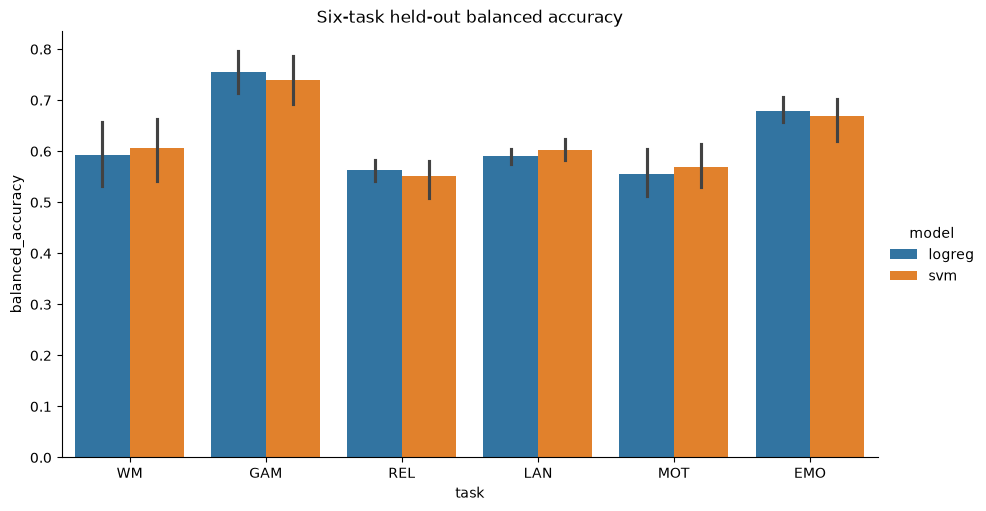

In [42]:
from sklearn.metrics import balanced_accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

def report_results(fold_scores, predictions):

    print("Fold-level balanced accuracy")

    display(
        fold_scores.groupby(
            ["task", "model"]
        )["balanced_accuracy"].agg(
            ["mean", "std", "count"]
        )
    )

    rows = []

    for (task, model, subject), g in predictions.groupby(
        ["task", "model", "subject"]
    ):

        rows.append({
            "task": task,
            "model": model,
            "subject": subject,
            "n": len(g),
            "balanced_accuracy": balanced_accuracy_score(
                g["y_true"],
                g["y_pred"]
            )
        })

    subject_scores = pd.DataFrame(rows)

    display(subject_scores.head())

    return subject_scores


subject_scores = report_results(
    full_folds,
    full_preds
)

subject_scores.to_csv(
    "all_roi_subject_scores.csv",
    index=False
)

sns.catplot(
    data=full_folds,
    x="task",
    y="balanced_accuracy",
    hue="model",
    kind="bar",
    height=5,
    aspect=1.8
)

plt.title("Six-task held-out balanced accuracy")
plt.show()

In [45]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    r"C:\Users\akshi\Desktop\phd-iit-jodhpur\Semester-1\Machine Learning"
)

assert PROJECT_DIR.exists(), f"Folder not found: {PROJECT_DIR}"

os.chdir(PROJECT_DIR)

print("Current working directory:", Path.cwd())

Current working directory: C:\Users\akshi\Desktop\phd-iit-jodhpur\Semester-1\Machine Learning


In [46]:
from pathlib import Path
import zipfile

# Project directory
PROJECT_DIR = Path(
    r"C:\Users\akshi\Desktop\phd-iit-jodhpur\Semester-1\Machine Learning"
)

# Folder for saved results
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Find output files
output_files = list(PROJECT_DIR.glob("*.csv"))

# Include feature matrix if available
feature_file = PROJECT_DIR / "hcp_features_activity.npy"

if feature_file.exists():
    output_files.append(feature_file)

# Create ZIP
zip_path = RESULTS_DIR / "hcp_classification_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for file in output_files:
        z.write(file, arcname=file.name)

print("ZIP created successfully!")
print("Saved at:", zip_path)
print("Files included:", len(output_files))

for file in output_files:
    print(" -", file.name)

ZIP created successfully!
Saved at: C:\Users\akshi\Desktop\phd-iit-jodhpur\Semester-1\Machine Learning\results\hcp_classification_results.zip
Files included: 7
 - all_roi_fold_scores.csv
 - all_roi_predictions.csv
 - all_roi_subject_scores.csv
 - hcp_block_metadata.csv
 - roi_ablation_fold_scores.csv
 - roi_ablation_predictions.csv
 - hcp_features_activity.npy
